# Лабораторная работа № 2. Наложение и удаление шума

**Цель:** добавить к изображению гауссовский и равномерный аддитивный шум, проверить медианный, гауссовский, билатеральный фильтры и фильтр нелокальных средних с разными параметрами, а затем сравнить результаты.

> Для запуска положите файл `sar_1(2).jpg` в ту же папку, что и этот ноутбук. В комплекте к ноутбуку этот файл приложен.

## 1. Импорт библиотек

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

SEED = 42
rng = np.random.default_rng(SEED)

print("OpenCV:", cv2.__version__)

OpenCV: 4.13.0


## 2. Загрузка исходного изображения

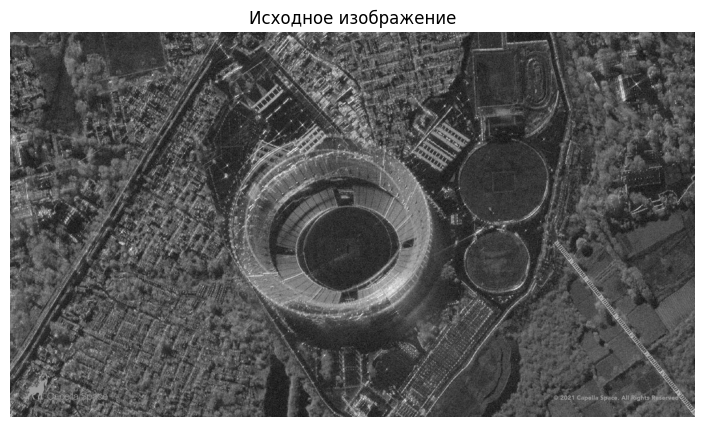

Размер изображения: (675, 1200)


In [2]:
image_path = "sar_1(2).jpg"
image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(
        f"Не удалось найти {image_path}. Положите изображение рядом с ноутбуком."
    )

image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 5))
plt.imshow(image_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis("off")
plt.show()

print("Размер изображения:", image_gray.shape)

## 3. Добавление шума

В задании указаны гауссовский и постоянный шум. Для второго эксперимента используем равномерно распределённую положительную добавку: это соответствует примечанию в приложенных материалах о положительных шумовых составляющих. После сложения значения ограничиваются диапазоном 0–255.

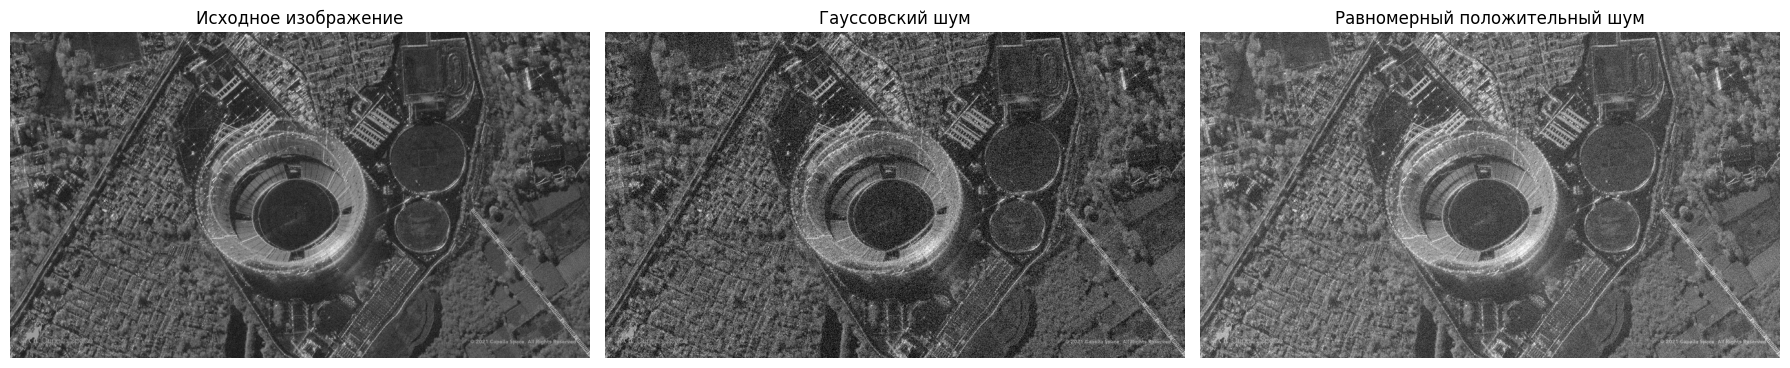

In [3]:
# Гауссовский шум: среднее 0, стандартное отклонение 25.
gaussian_noise = rng.normal(
    loc=0.0, scale=25.0, size=image_gray.shape
).astype(np.float32)

image_gaussian_noisy = np.clip(
    image_gray.astype(np.float32) + gaussian_noise, 0, 255
).astype(np.uint8)

# Равномерный положительный аддитивный шум в диапазоне [0, 50].
uniform_noise = rng.uniform(
    low=0.0, high=50.0, size=image_gray.shape
).astype(np.float32)

image_uniform_noisy = np.clip(
    image_gray.astype(np.float32) + uniform_noise, 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
images = [image_gray, image_gaussian_noisy, image_uniform_noisy]
titles = ["Исходное изображение", "Гауссовский шум", "Равномерный положительный шум"]
for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Функции фильтрации и оценки качества

Используем две метрики:
- **MSE** — среднеквадратичная ошибка; чем меньше значение, тем ближе результат к исходному изображению.
- **SSIM** — структурное сходство; чем ближе значение к 1, тем лучше сохранена структура изображения.

In [4]:
def apply_filters(noisy_image):
    """Возвращает результаты фильтров для заданного зашумлённого изображения."""
    results = {}

    # Медианный фильтр: размер окна должен быть нечётным.
    for k in (3, 5, 7):
        results[f"Median k={k}"] = cv2.medianBlur(noisy_image, k)

    # Гауссовский фильтр.
    for k in (3, 5, 7):
        results[f"Gaussian k={k}"] = cv2.GaussianBlur(noisy_image, (k, k), 0)

    # Билатеральный фильтр: меняем диаметр окрестности и параметры сигмы.
    for d, sigma in ((5, 40), (9, 75), (13, 100)):
        results[f"Bilateral d={d}, sigma={sigma}"] = cv2.bilateralFilter(
            noisy_image, d, sigma, sigma
        )

    # Фильтр нелокальных средних: проверяем несколько значений h.
    for h in (5, 10, 15):
        results[f"NLM h={h}"] = cv2.fastNlMeansDenoising(
            noisy_image, None, h, 7, 21
        )

    return results


def evaluate_results(original, noisy, filtered_results, noise_name):
    rows = []
    rows.append({
        "Шум": noise_name,
        "Фильтр": "Без фильтра",
        "MSE": mean_squared_error(original, noisy),
        "SSIM": structural_similarity(original, noisy, data_range=255)
    })

    for filter_name, filtered in filtered_results.items():
        rows.append({
            "Шум": noise_name,
            "Фильтр": filter_name,
            "MSE": mean_squared_error(original, filtered),
            "SSIM": structural_similarity(original, filtered, data_range=255)
        })
    return rows

## 5. Фильтрация гауссовского шума

In [5]:
gaussian_results = apply_filters(image_gaussian_noisy)
rows_gaussian = evaluate_results(
    image_gray, image_gaussian_noisy, gaussian_results, "Гауссовский"
)

# Таблица отсортирована по MSE: меньше — лучше.
df_gaussian = pd.DataFrame(rows_gaussian).sort_values("MSE").reset_index(drop=True)
display(df_gaussian.round({"MSE": 2, "SSIM": 4}))

best_gaussian_mse = df_gaussian.iloc[0]
best_gaussian_ssim = df_gaussian.loc[df_gaussian["SSIM"].idxmax()]
print("Лучший по MSE:", best_gaussian_mse["Фильтр"])
print("Лучший по SSIM:", best_gaussian_ssim["Фильтр"])

,Шум,Фильтр,MSE,SSIM
0,Гауссовский,Gaussian k=3,150.70,0.7234
1,Гауссовский,Gaussian k=5,156.92,0.7060
2,Гауссовский,"Bilateral d=5, sigma=40",187.28,0.6835
3,Гауссовский,Gaussian k=7,188.83,0.6481
4,Гауссовский,"Bilateral d=9, sigma=75",201.12,0.6137
5,Гауссовский,Median k=3,210.29,0.6371
6,Гауссовский,Median k=5,240.02,0.5615
7,Гауссовский,Median k=7,285.57,0.4833
8,Гауссовский,"Bilateral d=13, sigma=100",285.82,0.4840
9,Гауссовский,NLM h=15,421.03,0.5596


Лучший по MSE: Gaussian k=3
Лучший по SSIM: Gaussian k=3


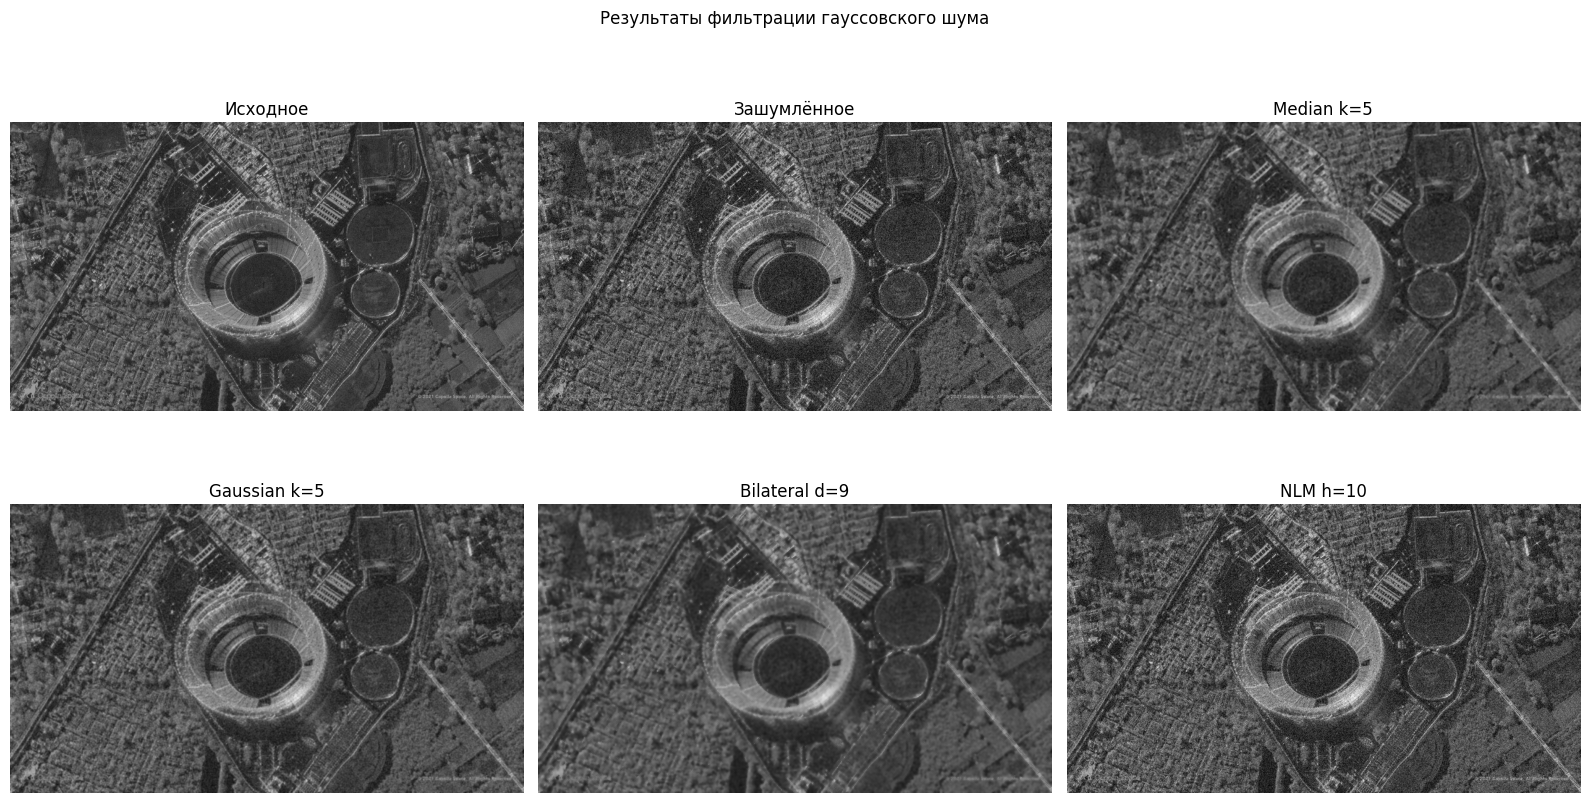

In [6]:
# Визуальное сравнение результатов для гауссовского шума.
selected_gaussian = [
    ("Исходное", image_gray),
    ("Зашумлённое", image_gaussian_noisy),
    ("Median k=5", gaussian_results["Median k=5"]),
    ("Gaussian k=5", gaussian_results["Gaussian k=5"]),
    ("Bilateral d=9", gaussian_results["Bilateral d=9, sigma=75"]),
    ("NLM h=10", gaussian_results["NLM h=10"]),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (title, img) in zip(axes.ravel(), selected_gaussian):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("Результаты фильтрации гауссовского шума")
plt.tight_layout()
plt.show()

## 6. Фильтрация равномерного положительного шума

In [7]:
uniform_results = apply_filters(image_uniform_noisy)
rows_uniform = evaluate_results(
    image_gray, image_uniform_noisy, uniform_results, "Равномерный положительный"
)

df_uniform = pd.DataFrame(rows_uniform).sort_values("MSE").reset_index(drop=True)
display(df_uniform.round({"MSE": 2, "SSIM": 4}))

best_uniform_mse = df_uniform.iloc[0]
best_uniform_ssim = df_uniform.loc[df_uniform["SSIM"].idxmax()]
print("Лучший по MSE:", best_uniform_mse["Фильтр"])
print("Лучший по SSIM:", best_uniform_ssim["Фильтр"])

,Шум,Фильтр,MSE,SSIM
0,Равномерный положительный,"Bilateral d=5, sigma=40",664.66,0.7654
1,Равномерный положительный,NLM h=15,693.47,0.7101
2,Равномерный положительный,Gaussian k=3,694.44,0.7821
3,Равномерный положительный,Gaussian k=5,725.89,0.7265
4,Равномерный положительный,Median k=3,733.23,0.6852
5,Равномерный положительный,NLM h=10,753.71,0.7304
6,Равномерный положительный,Gaussian k=7,771.86,0.6451
7,Равномерный положительный,Median k=5,784.56,0.5662
8,Равномерный положительный,"Bilateral d=9, sigma=75",790.84,0.5691
9,Равномерный положительный,Без фильтра,807.95,0.6713


Лучший по MSE: Bilateral d=5, sigma=40
Лучший по SSIM: Gaussian k=3


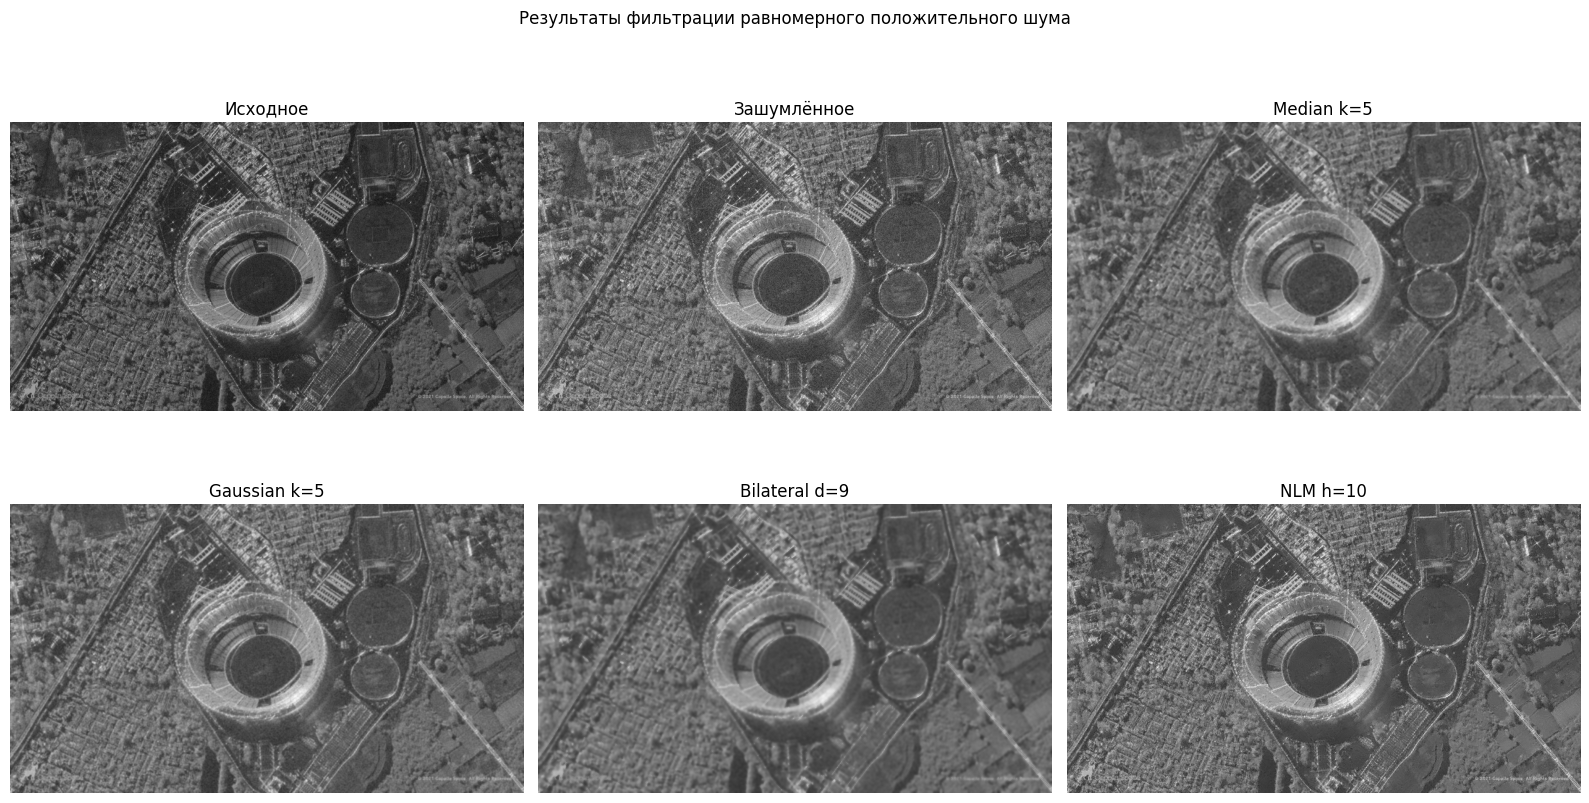

In [8]:
# Визуальное сравнение результатов для равномерного шума.
selected_uniform = [
    ("Исходное", image_gray),
    ("Зашумлённое", image_uniform_noisy),
    ("Median k=5", uniform_results["Median k=5"]),
    ("Gaussian k=5", uniform_results["Gaussian k=5"]),
    ("Bilateral d=9", uniform_results["Bilateral d=9, sigma=75"]),
    ("NLM h=10", uniform_results["NLM h=10"]),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (title, img) in zip(axes.ravel(), selected_uniform):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("Результаты фильтрации равномерного положительного шума")
plt.tight_layout()
plt.show()

## 7. Общая таблица и выбор лучшего результата

Для каждого типа шума сравним все фильтры по MSE и SSIM. Не следует заранее объявлять один фильтр лучшим: вывод делается по фактическим значениям метрик и визуальному сравнению.

In [9]:
all_results = pd.DataFrame(rows_gaussian + rows_uniform)
display(all_results.sort_values(["Шум", "MSE"]).round({"MSE": 2, "SSIM": 4}))

for noise_name in all_results["Шум"].unique():
    subset = all_results[all_results["Шум"] == noise_name]
    best_mse = subset.loc[subset["MSE"].idxmin()]
    best_ssim = subset.loc[subset["SSIM"].idxmax()]
    print(f"\n{noise_name} шум:")
    print(f"  Минимальный MSE: {best_mse['Фильтр']} (MSE={best_mse['MSE']:.2f})")
    print(f"  Максимальный SSIM: {best_ssim['Фильтр']} (SSIM={best_ssim['SSIM']:.4f})")

,Шум,Фильтр,MSE,SSIM
4,Гауссовский,Gaussian k=3,150.70,0.7234
5,Гауссовский,Gaussian k=5,156.92,0.7060
7,Гауссовский,"Bilateral d=5, sigma=40",187.28,0.6835
6,Гауссовский,Gaussian k=7,188.83,0.6481
8,Гауссовский,"Bilateral d=9, sigma=75",201.12,0.6137
1,Гауссовский,Median k=3,210.29,0.6371
2,Гауссовский,Median k=5,240.02,0.5615
3,Гауссовский,Median k=7,285.57,0.4833
9,Гауссовский,"Bilateral d=13, sigma=100",285.82,0.4840
12,Гауссовский,NLM h=15,421.03,0.5596



Гауссовский шум:
  Минимальный MSE: Gaussian k=3 (MSE=150.70)
  Максимальный SSIM: Gaussian k=3 (SSIM=0.7234)

Равномерный положительный шум:
  Минимальный MSE: Bilateral d=5, sigma=40 (MSE=664.66)
  Максимальный SSIM: Gaussian k=3 (SSIM=0.7821)


## 8. Вывод

После запуска ноутбука заполните вывод по полученным таблицам:

1. Для гауссовского шума лучший результат по MSE показал **[впишите название фильтра из таблицы]**, а по SSIM — **[впишите название фильтра]**.
2. Для равномерного положительного шума лучший результат по MSE показал **[впишите название фильтра]**, а по SSIM — **[впишите название фильтра]**.
3. Результаты разных метрик могут отличаться: MSE оценивает численную ошибку пикселей, а SSIM — сходство структуры.
4. Итоговый выбор фильтра следует подтвердить визуальным сравнением изображений.

**Важно:** не оставляйте квадратные скобки в окончательном отчёте — замените их результатами, которые вы получите после запуска всех ячеек.